In [18]:
import sys, os
sys.path.append(os.path.abspath(".."))   # pour pouvoir importer des fonctions depuis utils qui est à la racine

import torch
import torch.nn as nn
from torchvision import transforms
import matplotlib.pyplot as plt
from tqdm import tqdm
from IPython.display import clear_output
from torch.utils.data import DataLoader
import os
from utils import moving_average, get_device, ImageDataset, random_90_rotation

In [19]:
device = get_device()
print(f"Using device: {device}")

# Choisir le GPU et vérifier
torch.cuda.set_device(0)
print(torch.cuda.current_device())  # doit afficher le numéro choisi dans torch.cuda.set_device()
print(torch.cuda.get_device_name(torch.cuda.current_device()))

Using device: cuda
0
Tesla V100S-PCIE-32GB


In [20]:
batch_size = 512
n_epochs = 10
n_classes = 5
crop_size = 32

In [21]:
transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.Lambda(random_90_rotation),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])

train_dataset = ImageDataset(partial_path="../data/dataset_crops/train_32x32", transform=transform)
val_dataset = ImageDataset(partial_path="../data/dataset_crops/val_32x32", transform=transform)

print(f"taille de train_dataset : {len(train_dataset)}   taille de val_dataset : {len(val_dataset)}")

taille de train_dataset : 455135   taille de val_dataset : 99236


In [22]:
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=8)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=True, num_workers=4)

train_iterator = iter(train_loader)
val_iterator = iter(val_loader)

In [ ]:
from torchvision.models import resnet18

resnet = resnet18()
# remplacer la dernière couche pour avoir le bon nombre de classe et pas les 1000 de ImageNet
in_features = resnet.fc.in_features
resnet.fc = nn.Linear(in_features, n_classes)

# load the resnet parameters
checkpoint = torch.load("../divers/weights/resnet_sur_crops_sat_32x32_checkpoint10.pth", map_location="cpu")
resnet.load_state_dict(checkpoint["model_state_dict"])

resnet = resnet.to(device)
resnet.eval()

resnet_minus_last_layer = nn.Sequential(*list(resnet.children())[:-1])

print(f"Total parameters in the model: {sum(p.numel() for p in resnet.parameters())/1e6:.6f} million")

Total parameters in the resnet: 11.179077 million


In [24]:
import torch.nn.functional as F

class LinearSAE(nn.Module):

    def __init__(self, d_in, k, λ):
        super().__init__()
        self.enc = nn.Linear(d_in, k, bias=False)
        self.dec = nn.Linear(k, d_in, bias=False)
        self.λ   = λ

        nn.init.kaiming_normal_(self.enc.weight, nonlinearity='relu')
        nn.init.normal_(self.dec.weight, 0, 0.01)

    def forward(self, x):
        z = F.relu(self.enc(x))
        x_hat = self.dec(z)
        return x_hat, z

    def loss(self, x_hat, x, z):
        rec   = F.mse_loss(x_hat, x)
        spars = z.abs().mean()
        return rec + self.λ * spars, rec.item(), spars.item()

In [25]:
sae = LinearSAE(d_in=512, k=2048, λ=0.5).to(device)
optimizer_sae = torch.optim.AdamW(sae.parameters(), lr=3e-4, fused=True)

total_params = sum(p.numel() for p in sae.parameters())
print(f"Total parameters in the sae: {total_params/1e6:.6f} million")

train_loss_list, val_loss_list = [], []
train_rec_loss_list, val_rec_loss_list = [], []
train_spars_loss_list, val_spars_loss_list = [], []
train_sparsity, val_sparsity = [], []

Total parameters in the sae: 2.097152 million


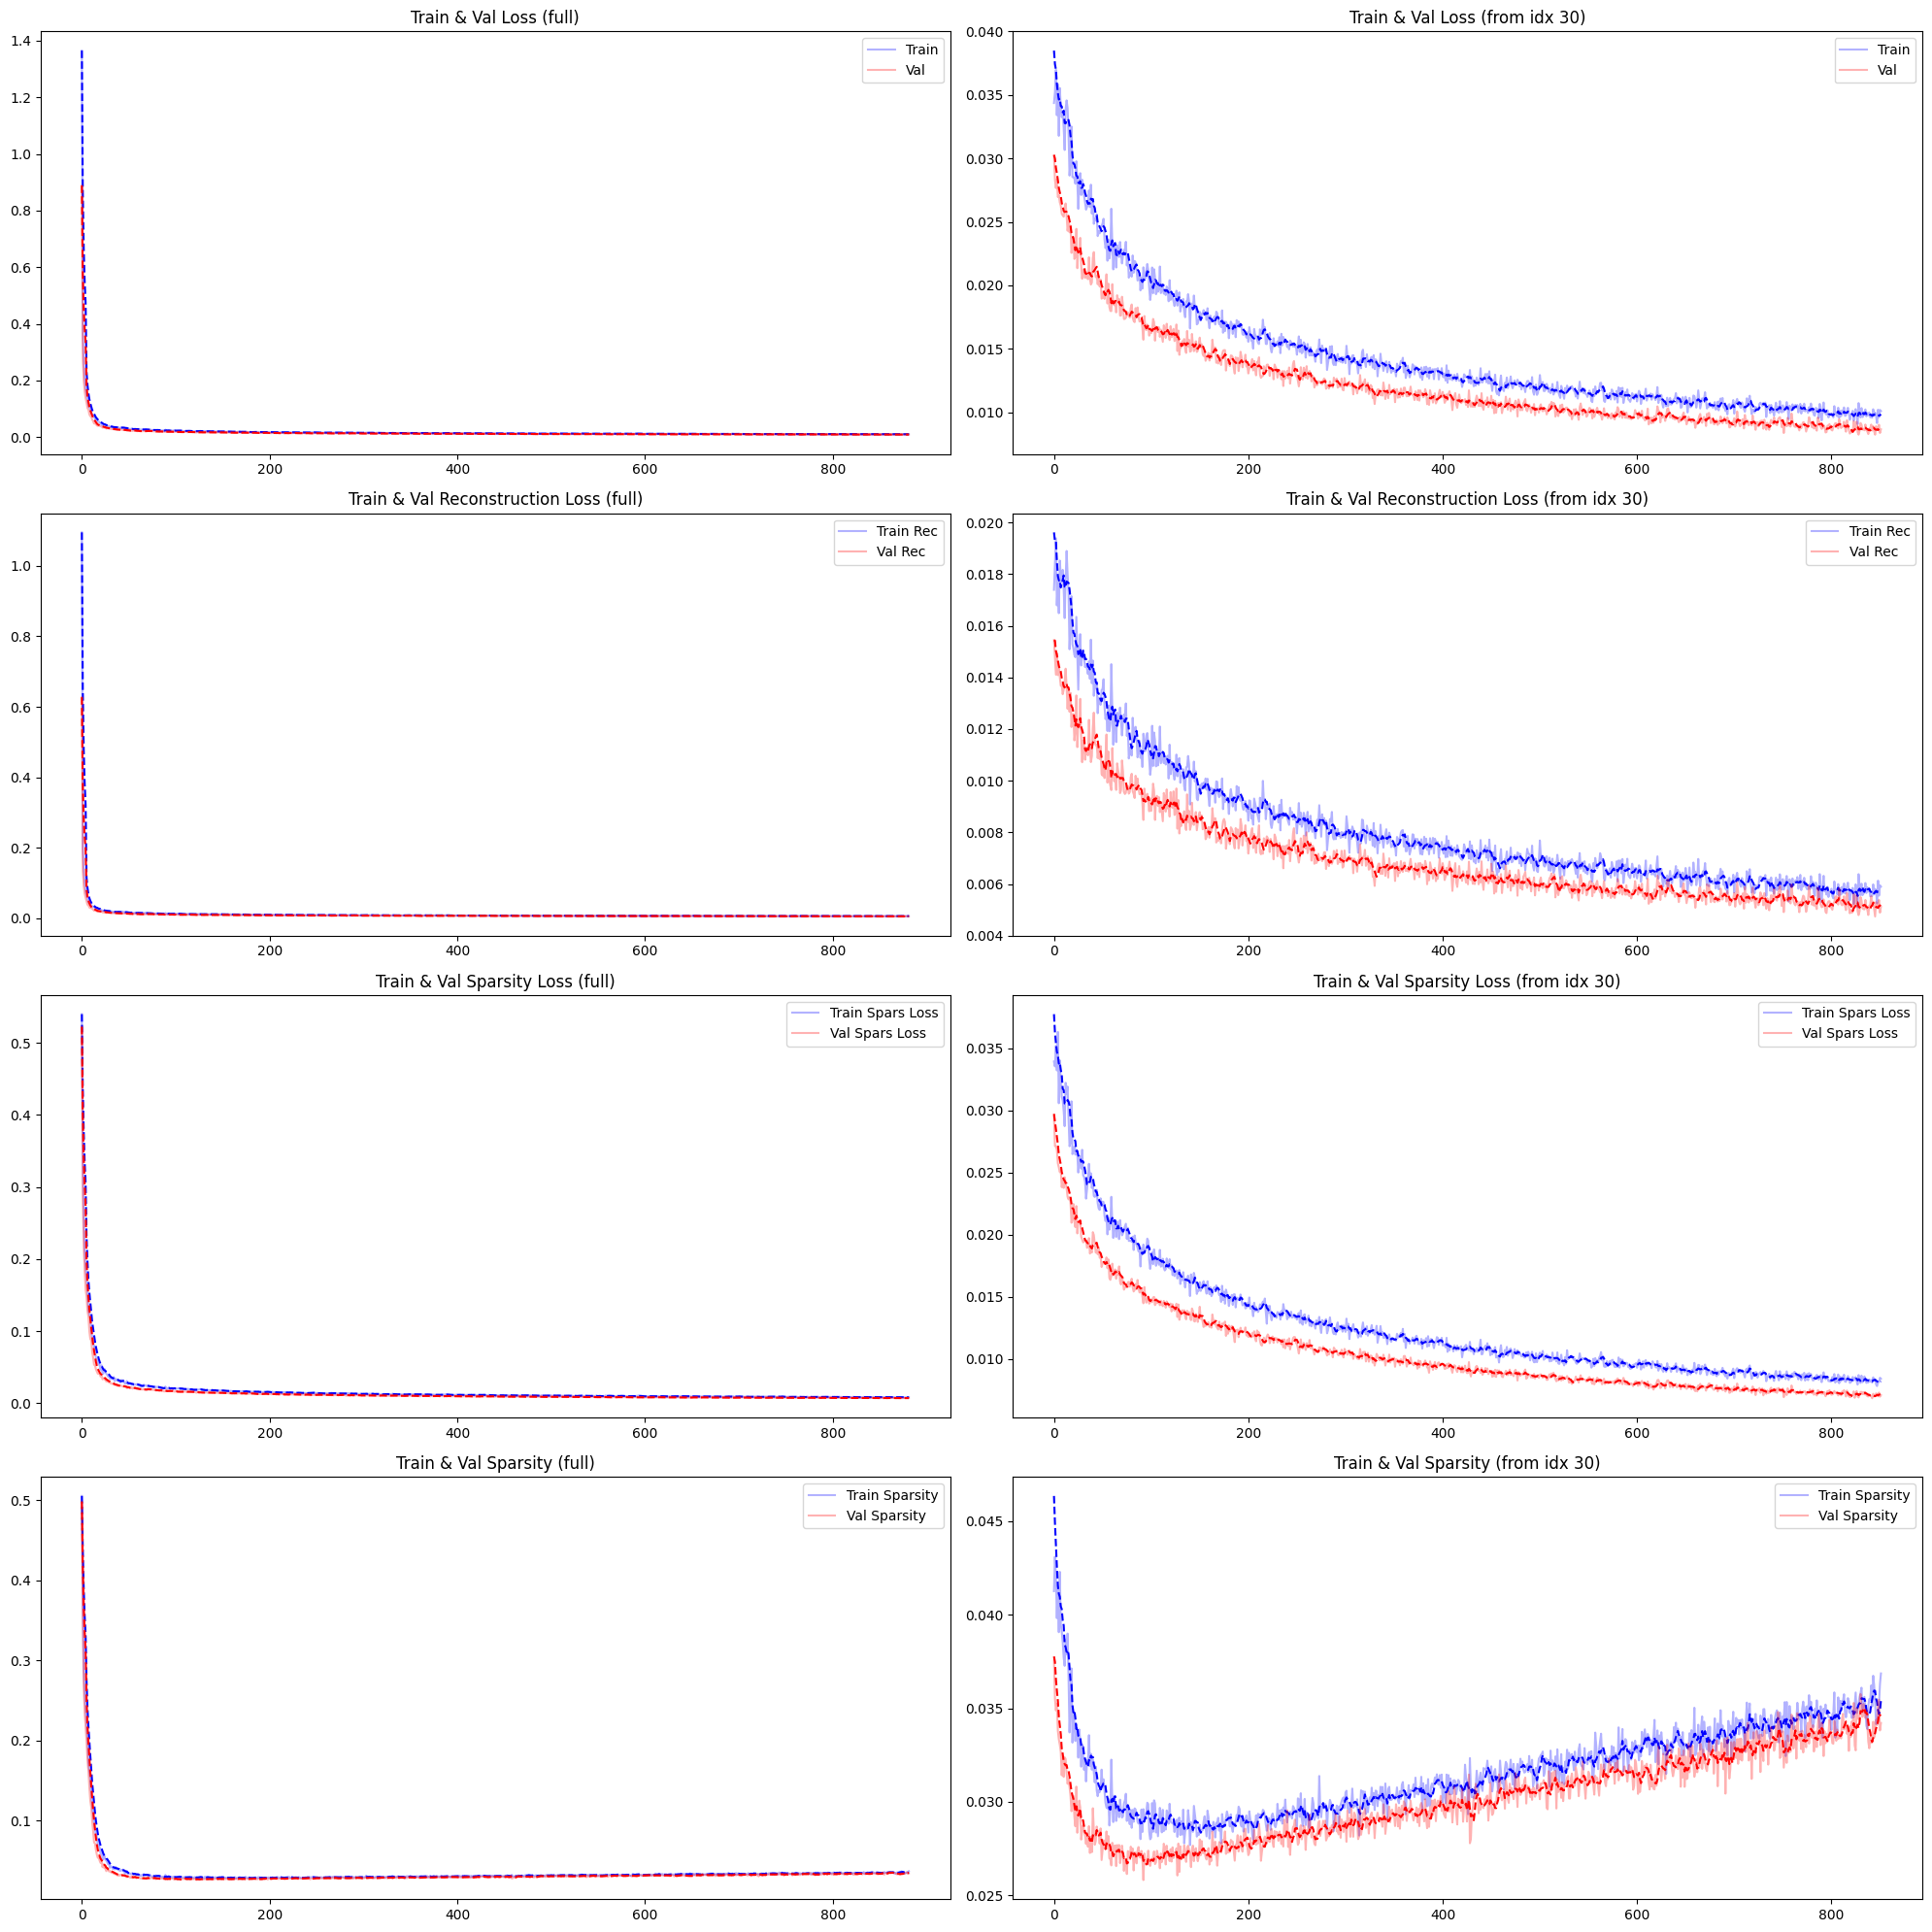

100%|██████████| 889/889 [01:28<00:00, 10.02it/s]


In [26]:
for epoch in range(n_epochs):
    for i, (imgs, attributs, classes) in tqdm(enumerate(train_loader), total=len(train_loader)):

        imgs, attributs, classes = imgs.to(device), attributs.to(device), classes.to(device)

        with torch.no_grad():
            # get the activation of the layer before the output
            x = resnet_minus_last_layer(imgs)
            x = x.view(x.shape[0], -1)  # flatten the output

        # put it in the sparse autoencoder
        x_hat, z = sae(x)

        loss, rec_loss, spars_loss = sae.loss(x_hat, x, z)

        optimizer_sae.zero_grad()
        loss.backward()
        optimizer_sae.step()



        if i % 10 == 0:
            train_loss_list.append(loss.item())
            train_rec_loss_list.append(rec_loss)
            train_spars_loss_list.append(spars_loss)
            train_sparsity.append((z > 0).sum().item() / z.numel())

            # get val loss
            sae.eval()
            with torch.no_grad():
                try:
                    imgs, attributs, classes = next(val_iterator)
                except StopIteration:
                    val_iterator = iter(val_loader)
                    imgs, attributs, classes = next(val_iterator)
                imgs, attributs, classes = imgs.to(device), attributs.to(device), classes.to(device)
                x = resnet_minus_last_layer(imgs)
                x = x.view(x.shape[0], -1)  # flatten the output
                x_hat, z = sae(x)
                loss, rec_loss, spars_loss = sae.loss(x_hat, x, z)
                val_loss_list.append(loss.item())
                val_rec_loss_list.append(rec_loss)
                val_spars_loss_list.append(spars_loss)
                val_sparsity.append((z > 0).sum().item() / z.numel())
            sae.train()



        if epoch % 1 == 0 and i % 200 == 0:

            start_idx = 30

            # Lissage
            train_loss_list_smoothed = moving_average(train_loss_list, w=5)
            val_loss_list_smoothed = moving_average(val_loss_list, w=5)

            train_rec_loss_list_smoothed = moving_average(train_rec_loss_list, w=5)
            val_rec_loss_list_smoothed = moving_average(val_rec_loss_list, w=5)

            train_spars_loss_list_smoothed = moving_average(train_spars_loss_list, w=5)
            val_spars_loss_list_smoothed = moving_average(val_spars_loss_list, w=5)

            train_sparsity_smoothed = moving_average(train_sparsity, w=5)
            val_sparsity_smoothed = moving_average(val_sparsity, w=5)

            clear_output(wait=True)

            plt.figure(figsize=(20, 20))  # plus grand pour 8 sous-plots

            # --- Loss globale ---
            plt.subplot(4, 2, 1)
            plt.plot(train_loss_list, c="blue", alpha=0.3, label="Train")
            plt.plot(train_loss_list_smoothed, c="blue", linestyle='--')
            plt.plot(val_loss_list, c="red", alpha=0.3, label="Val")
            plt.plot(val_loss_list_smoothed, c="red", linestyle='--')
            plt.title("Train & Val Loss (full)")
            plt.legend()

            plt.subplot(4, 2, 2)
            plt.plot(train_loss_list[start_idx:], c="blue", alpha=0.3, label="Train")
            plt.plot(train_loss_list_smoothed[start_idx:], c="blue", linestyle='--')
            plt.plot(val_loss_list[start_idx:], c="red", alpha=0.3, label="Val")
            plt.plot(val_loss_list_smoothed[start_idx:], c="red", linestyle='--')
            plt.title(f"Train & Val Loss (from idx {start_idx})")
            plt.legend()

            # --- Reconstruction loss ---
            plt.subplot(4, 2, 3)
            plt.plot(train_rec_loss_list, c="blue", alpha=0.3, label="Train Rec")
            plt.plot(train_rec_loss_list_smoothed, c="blue", linestyle='--')
            plt.plot(val_rec_loss_list, c="red", alpha=0.3, label="Val Rec")
            plt.plot(val_rec_loss_list_smoothed, c="red", linestyle='--')
            plt.title("Train & Val Reconstruction Loss (full)")
            plt.legend()

            plt.subplot(4, 2, 4)
            plt.plot(train_rec_loss_list[start_idx:], c="blue", alpha=0.3, label="Train Rec")
            plt.plot(train_rec_loss_list_smoothed[start_idx:], c="blue", linestyle='--')
            plt.plot(val_rec_loss_list[start_idx:], c="red", alpha=0.3, label="Val Rec")
            plt.plot(val_rec_loss_list_smoothed[start_idx:], c="red", linestyle='--')
            plt.title(f"Train & Val Reconstruction Loss (from idx {start_idx})")
            plt.legend()

            # --- Sparsity loss ---
            plt.subplot(4, 2, 5)
            plt.plot(train_spars_loss_list, c="blue", alpha=0.3, label="Train Spars Loss")
            plt.plot(train_spars_loss_list_smoothed, c="blue", linestyle='--')
            plt.plot(val_spars_loss_list, c="red", alpha=0.3, label="Val Spars Loss")
            plt.plot(val_spars_loss_list_smoothed, c="red", linestyle='--')
            plt.title("Train & Val Sparsity Loss (full)")
            plt.legend()

            plt.subplot(4, 2, 6)
            plt.plot(train_spars_loss_list[start_idx:], c="blue", alpha=0.3, label="Train Spars Loss")
            plt.plot(train_spars_loss_list_smoothed[start_idx:], c="blue", linestyle='--')
            plt.plot(val_spars_loss_list[start_idx:], c="red", alpha=0.3, label="Val Spars Loss")
            plt.plot(val_spars_loss_list_smoothed[start_idx:], c="red", linestyle='--')
            plt.title(f"Train & Val Sparsity Loss (from idx {start_idx})")
            plt.legend()

            # --- Sparsity (valeurs réelles, pas la loss) ---
            plt.subplot(4, 2, 7)
            plt.plot(train_sparsity, c="blue", alpha=0.3, label="Train Sparsity")
            plt.plot(train_sparsity_smoothed, c="blue", linestyle='--')
            plt.plot(val_sparsity, c="red", alpha=0.3, label="Val Sparsity")
            plt.plot(val_sparsity_smoothed, c="red", linestyle='--')
            plt.title("Train & Val Sparsity (full)")
            plt.legend()

            plt.subplot(4, 2, 8)
            plt.plot(train_sparsity[start_idx:], c="blue", alpha=0.3, label="Train Sparsity")
            plt.plot(train_sparsity_smoothed[start_idx:], c="blue", linestyle='--')
            plt.plot(val_sparsity[start_idx:], c="red", alpha=0.3, label="Val Sparsity")
            plt.plot(val_sparsity_smoothed[start_idx:], c="red", linestyle='--')
            plt.title(f"Train & Val Sparsity (from idx {start_idx})")
            plt.legend()

            plt.tight_layout()
            plt.show()


In [ ]:
# # sauvegarder les poids du modèle et les paramètres d'entraînement

# torch.save({
#     'model_state_dict': {k: v.cpu() for k, v in sae.state_dict().items()},
#     'optimizer_state_dict': optimizer_sae.state_dict(),
# }, f"weights/sae_{crop_size}x{crop_size}_checkpoint2.pth")

In [51]:
imgs, attributs, classes = next(train_iterator)

imgs, attributs, classes = imgs.to(device), attributs.to(device), classes.to(device)

with torch.no_grad():
    # get the activation of the layer before the output
    x = resnet_minus_last_layer(imgs)
    x = x.view(x.shape[0], -1)  # flatten the output

    # put it in the sparse autoencoder
    x_hat, z = sae(x)


x0, x_hat0 = x[0], x_hat[0]

for i in range(10):
    print(x0[i].item(), x_hat0[i].item(), (x0[i].item() - x_hat0[i].item())**2)

0.975834846496582 0.9280166625976562 0.002286578711391485
1.0266958475112915 1.0053378343582153 0.00045616472584697476
1.03739333152771 1.0050017833709717 0.0010492123919902951
1.6058051586151123 1.6916003227233887 0.007360810184366073
1.2403653860092163 1.2698988914489746 0.0008722279435602331
1.0567560195922852 1.0628355741500854 3.6960983621270316e-05
0.7443951964378357 0.7946537733078003 0.0025259245489941407
2.174452781677246 2.1608872413635254 0.0001840238840031816
0.7393918037414551 0.7592188715934753 0.00039311261960861543
1.3391445875167847 1.4086750745773315 0.004834488630876876


In [52]:
print((z > 0).sum().item()/z.numel())
print(z.flatten().tolist()[:100])

0.03472137451171875
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.2571101188659668, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0023419037461280823, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.03861532360315323, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.07504242658615112, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
